# 01 — Introduction to Deep Learning and Keras

### From biological questions to trainable neural networks

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 01 of 12  
**Level:** Beginner → foundational  
**Primary tools:** Python, NumPy, Matplotlib, Keras 3  
**Example domain:** Synthetic gene-expression measurements (educational data only)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Distinguish Artificial Intelligence, Machine Learning, and Deep Learning.
2. Explain what an artificial neuron and a neural network do.
3. Describe features, weights, bias, activations, layers, parameters, and predictions.
4. Explain—at a conceptual level—training, loss, optimization, and generalization.
5. Identify what Keras is and how Keras 3 relates to its computational backends.
6. Build, train, and evaluate a small neural network using the Keras API.
7. Recognize the limitations of a toy dataset and avoid interpreting it as biological evidence.

> **Important:** This is the first notebook in a self-contained Keras curriculum. You do not need PyTorch or prior deep-learning experience. We will introduce only the mathematics needed to understand the examples; the next notebooks develop these topics in greater depth.

## 1. The big picture: AI, Machine Learning, and Deep Learning

These terms are related, but they are not interchangeable.

- **Artificial Intelligence (AI)** is the broad field concerned with building systems that perform tasks associated with intelligent behavior.
- **Machine Learning (ML)** is a subset of AI. Instead of specifying every decision rule manually, we use data to estimate a model that performs a task.
- **Deep Learning (DL)** is a family of machine-learning methods based on neural networks with multiple computational layers.

A useful way to remember the relationship is:

**AI ⊃ Machine Learning ⊃ Deep Learning**

### 1.1 A conventional programming approach

In conventional programming, a developer writes explicit rules:

1. Receive input.
2. Apply predefined rules.
3. Produce an output.

This works well when the rules are known and can be expressed reliably.

### 1.2 A machine-learning approach

In supervised machine learning, we provide examples containing inputs and known targets. A learning algorithm estimates a function that maps inputs to outputs.

For example, imagine a dataset containing gene-expression measurements from samples labelled as belonging to one of two experimental groups. A model receives the measurements and learns patterns associated with the labels.

The model does **not** automatically discover biological causation. It learns statistical associations in the training data. Experimental design, confounding variables, data quality, and validation determine how meaningful those associations are.

## 2. What is a neural network?

An artificial neural network (ANN) is a parameterized computational model that transforms input data through a sequence of mathematical operations to produce an output.

A simple feed-forward neural network commonly consists of three types of layers:

- **Input layer:** Receives the input features.
- **Hidden layers:** Learn intermediate representations from the input data.
- **Output layer:** Produces predictions in a form appropriate for the task.

Each layer contains units, commonly called *neurons*. A neuron computes a weighted sum of its inputs, adds a bias, and applies an activation function.

For a single neuron:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

$$
a = \phi(z)
$$

Where:

- $x_i$ represents an input feature.
- $w_i$ represents the corresponding learnable weight.
- $b$ is the bias.
- $\phi$ is the activation function.
- $a$ is the neuron's output.

The weights and biases are called **parameters**. During training, these parameters are updated to minimize a selected loss function.

### 2.1 Why use an activation function?

Without nonlinear activation functions, stacking multiple linear layers is mathematically equivalent to a single linear transformation. Nonlinear activation functions allow neural networks to learn and represent more complex relationships in data.

Common activation functions include:

| Activation | Typical role | Key property |
|---|---|---|
| ReLU | Hidden layers | $\max(0,z)$ |
| Sigmoid | Binary classification output | Maps values to $(0,1)$ |
| Tanh | Hidden layers | Maps values to $(-1,1)$ |
| Softmax | Multiclass classification output | Produces a probability distribution |

We will explore these activation functions and their mathematical properties in detail in Notebook 02.

## 3. How does a network learn?

A neural network does not begin with biological knowledge. Its initial parameters are generally initialized numerically. Learning is an iterative optimization process.

A simplified training cycle is:

1. **Forward pass:** send a batch of inputs through the network to obtain predictions.
2. **Loss calculation:** compare predictions with known targets using a loss function.
3. **Backpropagation:** calculate how the loss changes with respect to each trainable parameter.
4. **Optimization step:** update parameters using an optimizer such as stochastic gradient descent or Adam.
5. **Repeat:** continue across batches and epochs.

### 3.1 Important terminology

- **Sample:** one observation, such as one biological specimen.
- **Feature:** one measured input variable, such as the expression value of a gene.
- **Target / label:** the value the model is asked to predict.
- **Batch:** a subset of samples processed in one training step.
- **Epoch:** one complete pass through the training dataset.
- **Loss:** a numerical measure of prediction error under a chosen objective.
- **Optimizer:** an algorithm that updates model parameters.
- **Validation set:** data used during development to monitor generalization and guide model selection.
- **Test set:** held-out data used for a final evaluation after model-development decisions are complete.

A lower training loss does not necessarily mean a better model. A model can memorize training examples and perform poorly on new samples. This is called **overfitting**.

## 4. What is Keras?

**Keras** is a high-level deep-learning API for defining, training, evaluating, and deploying neural-network models. Its design emphasizes readable model construction and a consistent workflow.

Keras 3 is multi-backend: it can run with different computational backends, including TensorFlow, JAX, and PyTorch. The Keras API and the backend are related but distinct:

- **Keras** provides the high-level model-building interface used in this learning path.
- A **backend** provides lower-level tensor operations and numerical computation.
- **TensorFlow** is one possible backend and is also a broader machine-learning ecosystem in its own right.

In this curriculum, we focus on learning Keras as an API. A later, separate TensorFlow directory will cover TensorFlow-specific concepts and workflows. You do not need to learn PyTorch to follow this Keras path.

Official documentation: <https://keras.io/>

## 5. Set up the environment

The examples in this notebook use **Keras 3 with the TensorFlow backend** to keep the initial setup straightforward.

If the packages are not installed in your environment, run the following cell. In some environments, installing packages requires restarting the notebook kernel.

For a reproducible project, record package versions and use a dedicated virtual environment rather than repeatedly changing a global Python installation.

In [9]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy matplotlib scikit-learn

In [11]:
# Select the backend BEFORE importing Keras.
# Keras reads this environment variable during initialization.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys
import numpy as np
import matplotlib.pyplot as plt
import keras

print("Python:", sys.version.split()[0])
print("Keras:", keras.__version__)
print("Keras backend:", keras.backend.backend())
print("NumPy:", np.__version__)

Python: 3.11.0
Keras: 3.15.1
Keras backend: tensorflow
NumPy: 2.4.6


### 5.1 Why set the backend before importing Keras?

Keras needs to know which backend to initialize. Set `KERAS_BACKEND` before `import keras`. If Keras has already been imported in the current kernel, changing the environment variable afterward may not switch the active backend. Restart the kernel and run the setup cell first.

For this notebook, the expected backend is `tensorflow`. If your environment reports a different backend, check the setup order and installed packages.

## 6. A first look at data: a small biological-style example

Before training a model, we need to understand what its input and target represent.

We will create a **synthetic** dataset with six features named like gene-expression measurements and a binary group label. The data are generated for teaching purposes. They are not real patient data, real gene measurements, or evidence about a biological mechanism.

Each row represents one hypothetical sample:

- six numerical features represent normalized expression-like measurements;
- the target is either `Group 0` or `Group 1`.

We use synthetic data here because this first notebook is about the learning workflow, not about making a biological claim. Later notebooks will use public biological datasets and discuss their provenance and limitations.

In [12]:
# Reproducibility: use a fixed random seed for this demonstration.
rng = np.random.default_rng(42)

n_samples = 800
n_features = 6

# Generate two synthetic groups with slightly different feature distributions.
n_per_group = n_samples // 2
group_0 = rng.normal(loc=0.0, scale=1.0, size=(n_per_group, n_features))
group_1 = rng.normal(loc=0.65, scale=1.0, size=(n_per_group, n_features))

X = np.vstack([group_0, group_1]).astype("float32")
y = np.concatenate([
    np.zeros(n_per_group, dtype="float32"),
    np.ones(n_per_group, dtype="float32")
])

# Shuffle samples while preserving the X-y correspondence.
indices = rng.permutation(n_samples)
X = X[indices]
y = y[indices]

feature_names = [f"Gene_{i+1}" for i in range(n_features)]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class counts:", {int(label): int((y == label).sum()) for label in np.unique(y)})
print("First sample:", X[0])
print("First target:", int(y[0]))

Feature matrix shape: (800, 6)
Target shape: (800,)
Class counts: {0: 400, 1: 400}
First sample: [ 0.20393062  1.6301908   0.93117315 -0.0475572  -0.21593988 -0.9974963 ]
First target: 1


### 6.1 Understand the Shape of the Data

For a tabular dataset, the feature matrix is typically represented as:

$$
X \in \mathbb{R}^{N \times F}
$$

where:

- $N$ is the number of samples (observations).
- $F$ is the number of features (input variables).

Each row of $X$ represents one sample, while each column represents one feature.

For binary classification, the target vector contains one binary label per sample:

$$
y \in \{0,1\}^{N}
$$

where $0$ and $1$ represent the two target classes.

The number of samples in $X$ and $y$ must always match:

$$
X.shape[0] = y.shape[0] = N
$$

**Important:** Each feature row must remain correctly associated with its corresponding target label throughout data shuffling, splitting, and preprocessing. Losing this alignment can lead to incorrect training and evaluation results.

In [13]:
# Inspect a few observations without requiring pandas.
for row_index in range(5):
    print(
        f"Sample {row_index + 1}: "
        f"features={np.round(X[row_index], 2)}, "
        f"target={int(y[row_index])}"
    )

Sample 1: features=[ 0.2   1.63  0.93 -0.05 -0.22 -1.  ], target=1
Sample 2: features=[ 0.42  1.24  0.41  1.97  1.29 -0.54], target=1
Sample 3: features=[-1.69 -0.83  0.25 -0.18 -0.25 -0.16], target=0
Sample 4: features=[ 1.93 -0.19  0.93 -0.99 -1.39  0.97], target=1
Sample 5: features=[ 2.43  2.27  1.01  1.11  1.44 -0.61], target=1


## 7. Split the data before fitting preprocessing steps

We will create training, validation, and test partitions.

- **Training data** are used to estimate model parameters.
- **Validation data** are used to monitor performance during development.
- **Test data** are reserved for the final evaluation.

A central rule is to fit preprocessing transformations on the training data only. Applying information from the validation or test sets while estimating preprocessing parameters can cause **data leakage**.

This toy dataset is already on a simple numerical scale, but we will still demonstrate standardization correctly.

In [14]:
# Shuffle once, then create disjoint partitions.
n = len(X)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

X_train_raw, y_train = X[:train_end], y[:train_end]
X_val_raw, y_val = X[train_end:val_end], y[train_end:val_end]
X_test_raw, y_test = X[val_end:], y[val_end:]

# Estimate scaling parameters from training data only.
train_mean = X_train_raw.mean(axis=0)
train_std = X_train_raw.std(axis=0)
train_std = np.where(train_std == 0, 1.0, train_std)

X_train = (X_train_raw - train_mean) / train_std
X_val = (X_val_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (560, 6) (560,)
Validation: (120, 6) (120,)
Test: (120, 6) (120,)


In [15]:
# Verify that the partitions are disjoint and preprocessing used train statistics.
assert len(X_train) + len(X_val) + len(X_test) == n
assert X_train.shape[1] == n_features
assert X_val.shape[1] == n_features
assert X_test.shape[1] == n_features

print("Partition checks passed.")
print("Training feature means after scaling:", np.round(X_train.mean(axis=0), 3))
print("Training feature standard deviations:", np.round(X_train.std(axis=0), 3))

Partition checks passed.
Training feature means after scaling: [-0. -0.  0. -0. -0. -0.]
Training feature standard deviations: [1. 1. 1. 1. 1. 1.]


## 8. Build the first neural network with Keras

We will use a small **Multilayer Perceptron (MLP)** for binary classification.

Architecture:

- Input: 6 numerical features
- Hidden layer 1: 16 units with ReLU
- Hidden layer 2: 8 units with ReLU
- Output: 1 unit with Sigmoid

The output is a number between 0 and 1. We interpret it as the model's estimated probability for class 1, under this model and training setup.

### 8.1 Why these choices?

- `Dense` creates a fully connected layer.
- `relu` introduces nonlinearity in hidden layers.
- `sigmoid` is a common output activation for binary classification.
- `binary_crossentropy` is a standard loss for binary targets.
- `adam` is an adaptive optimization algorithm.

These are reasonable introductory choices, not universal rules. Model architecture and loss function must match the task, labels, and data-generating process.

In [16]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(n_features,), name="expression_features"),
        keras.layers.Dense(16, activation="relu", name="hidden_1"),
        keras.layers.Dense(8, activation="relu", name="hidden_2"),
        keras.layers.Dense(1, activation="sigmoid", name="binary_output"),
    ],
    name="intro_biological_classifier",
)

model.summary()

Model: "intro_biological_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

### 8.2 Understand the Model Summary

The `model.summary()` method provides an overview of the neural network architecture, including each layer's output shape and the number of parameters.

For a `Dense` layer with $d$ input features and $u$ units, the total number of trainable parameters is:

$$
P = (d \times u) + u
$$

The first term represents the weights, while the second term represents the bias assigned to each unit.

For example, consider a `Dense` layer that maps 6 input features to 16 units:

$$
P = (6 \times 16) + 16
$$

$$
P = 96 + 16 = 112
$$

Therefore, the layer contains **112 trainable parameters**.

**Important:** A larger number of parameters does not necessarily indicate a better model. Model complexity should be considered in relation to the amount, quality, and structure of the available training data. Models with excessive parameters may overfit, particularly when training data is limited.

## 9. Compile the model

In Keras, `compile()` configures the learning process. It specifies:

- **Optimizer:** how trainable parameters are updated.
- **Loss:** what quantity the model attempts to minimize.
- **Metrics:** additional quantities reported during training and evaluation.

The loss guides optimization. Metrics help us interpret performance. A metric is not necessarily the same thing as the objective being optimized.

In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
    ],
)

## 10. Train the model

The `fit()` method performs the training loop.

- `epochs` controls how many passes are made over the training data.
- `batch_size` controls how many observations are processed per training step.
- `validation_data` supplies data used to monitor performance after each epoch.

The validation set is not used to directly update the model's weights in this standard workflow.

In [18]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    verbose=1,
)

Epoch 1/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5000 - loss: 0.6506 - precision: 0.6154 - recall: 0.0283 - val_accuracy: 0.5917 - val_loss: 0.6202 - val_precision: 0.8333 - val_recall: 0.0943
Epoch 2/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5339 - loss: 0.6191 - precision: 0.7895 - recall: 0.1060 - val_accuracy: 0.6500 - val_loss: 0.5948 - val_precision: 0.8667 - val_recall: 0.2453
Epoch 3/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5982 - loss: 0.5952 - precision: 0.8222 - recall: 0.2615 - val_accuracy: 0.6750 - val_loss: 0.5742 - val_precision: 0.8182 - val_recall: 0.3396
Epoch 4/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6554 - loss: 0.5746 - precision: 0.8000 - recall: 0.4240 - val_accuracy: 0.7333 - val_loss: 0.5560 - val_precision: 0.8387 - val_recall: 0.4906
Epoch 5/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7321 - loss: 0.5553 - precision: 0.8244 - recall: 0.5972 - val_accuracy: 0.7667 - val_loss: 0.5400 - v

### 10.1 Inspect the training history

Keras returns a `History` object. Its `history` attribute stores the loss and metric values recorded during training.

Learning curves can help identify patterns such as:

- training and validation loss both decreasing;
- training loss decreasing while validation loss stops improving;
- unstable learning caused by optimization or data issues.

A curve alone does not prove why a model behaves in a particular way. It is a diagnostic signal that should be interpreted alongside the data, model, and evaluation design.

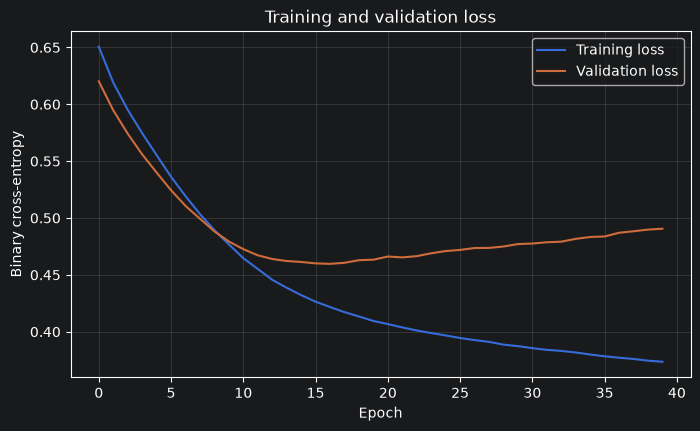

In [19]:
history_dict = history.history

plt.figure(figsize=(8, 4.5))
plt.plot(history_dict["loss"], label="Training loss")
plt.plot(history_dict["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training and validation loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

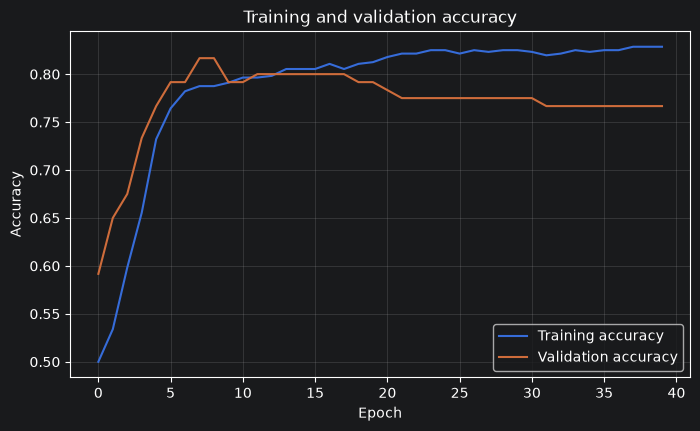

In [20]:
plt.figure(figsize=(8, 4.5))
plt.plot(history_dict["accuracy"], label="Training accuracy")
plt.plot(history_dict["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 11. Evaluate on the held-out test set

After training and development decisions are complete, evaluate the model on the test set.

The test set should not be repeatedly used to tune architecture, select epochs, or choose hyperparameters. Repeatedly making decisions based on test performance turns the test set into part of the development process and weakens its role as an independent evaluation.

In [21]:
test_results = model.evaluate(X_test, y_test, verbose=0, return_dict=True)

print("Test-set results")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name:>12}: {metric_value:.4f}")

Test-set results
    accuracy: 0.7917
        loss: 0.4587
   precision: 0.8197
      recall: 0.7812


In [22]:
# Convert predicted probabilities to class labels using a 0.5 threshold.
# This threshold is illustrative; threshold selection depends on the task.
test_probabilities = model.predict(X_test, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype("int32")
test_labels = y_test.astype("int32")

true_positive = int(np.sum((test_predictions == 1) & (test_labels == 1)))
true_negative = int(np.sum((test_predictions == 0) & (test_labels == 0)))
false_positive = int(np.sum((test_predictions == 1) & (test_labels == 0)))
false_negative = int(np.sum((test_predictions == 0) & (test_labels == 1)))

confusion_matrix = np.array([
    [true_negative, false_positive],
    [false_negative, true_positive],
])

print("Confusion matrix (rows = true class, columns = predicted class)")
print(confusion_matrix)

Confusion matrix (rows = true class, columns = predicted class)
[[45 11]
 [14 50]]


### 11.1 Interpret the result responsibly

The synthetic groups were deliberately generated with different feature distributions, so a model can learn a statistical signal. This does not mean the model has discovered a real disease signature, a causal gene, or a clinically useful biomarker.

In real biomedical work, evaluation should also consider:

- how samples were collected and labelled;
- whether multiple samples come from the same individual;
- batch effects and technical confounding;
- class imbalance and clinically relevant error costs;
- external validation on appropriately independent cohorts;
- uncertainty and reproducibility.

These topics will recur throughout the biological-data notebooks.

## 12. Make predictions for new observations

Once a model is trained, `predict()` can generate predictions for new observations with the same feature definition and preprocessing.

The new data must be transformed using the **training** mean and standard deviation—not statistics estimated from the new data.

In [23]:
# Demonstration: take two held-out observations as if they were new inputs.
new_samples_raw = X_test_raw[:2]
new_samples = (new_samples_raw - train_mean) / train_std

new_probabilities = model.predict(new_samples, verbose=0).ravel()

for index, probability in enumerate(new_probabilities, start=1):
    predicted_class = int(probability >= 0.5)
    print(
        f"Sample {index}: probability of Group 1 = {probability:.3f}; "
        f"predicted class = {predicted_class}"
    )

Sample 1: probability of Group 1 = 0.161; predicted class = 0
Sample 2: probability of Group 1 = 0.010; predicted class = 0


## 13. Save and reload a Keras model

A trained model can be saved for later use. The native Keras format uses the `.keras` extension.

For a complete reproducible workflow, remember that a model file alone does not document every preprocessing decision. In a real project, save or record the feature order, scaling parameters, label mapping, data version, and package versions as well.

In [24]:
model_path = "intro_biological_classifier.keras"

model.save(model_path)
print(f"Model saved to: {model_path}")

reloaded_model = keras.models.load_model(model_path)
reloaded_predictions = reloaded_model.predict(X_test[:3], verbose=0)

print("Reloaded model predictions:")
print(np.round(reloaded_predictions.ravel(), 3))

Model saved to: intro_biological_classifier.keras
Reloaded model predictions:
[0.161 0.01  0.096]


## 14. What did we learn?

In this notebook, we moved from the broad idea of deep learning to a working Keras model.

You have seen that:

1. Deep learning is based on neural networks with learnable parameters.
2. A neuron applies a weighted transformation followed by an activation function.
3. Training combines forward computation, a loss function, gradients, and parameter updates.
4. Keras provides a high-level API for defining and training neural networks.
5. Keras 3 is distinct from any one backend.
6. Data splitting and preprocessing must be designed to prevent leakage.
7. A successful run on synthetic data is a programming demonstration, not biological validation.

### Key terms

| Term | Meaning |
|---|---|
| Feature | An input variable used by a model |
| Target | The value the model is trained to predict |
| Weight | A trainable coefficient |
| Bias | A trainable offset |
| Activation | A function applied to a neuron's pre-activation value |
| Epoch | One pass through the training dataset |
| Batch size | Number of samples processed in one training step |
| Loss | Objective measuring prediction error |
| Optimizer | Algorithm that updates model parameters |
| Generalization | Performance on relevant unseen data |

## 15. Exercises

Try to answer the conceptual questions before looking up the answers.

### Conceptual questions

1. Explain the relationship between AI, ML, and DL in your own words.
2. What is the role of a weight and a bias in a neuron?
3. Why do neural networks need nonlinear activation functions?
4. What is the difference between a loss function and a metric?
5. Why should the test set not be used repeatedly during model development?
6. Why is it inaccurate to describe the synthetic dataset in this notebook as real biological evidence?
7. What is the difference between Keras and its backend?

### Programming exercises

1. Change the hidden-layer widths from 16 and 8 to 32 and 16. Compare parameter counts and validation performance.
2. Train a model with only one hidden layer. What changes?
3. Change the batch size from 32 to 16 or 64. Compare the training curves.
4. Change the learning rate from `1e-3` to `1e-4`. Describe the observed effect.
5. Replace the sigmoid output with a two-unit softmax output and adapt the target representation and loss function. Explain why the output and loss must be compatible.
6. Add a seventh synthetic feature and update the model input shape. Verify that the workflow still runs.

### Research-thinking exercise

Imagine that the two labels represent biological conditions. List at least five reasons why a high test accuracy on one dataset might fail to translate to a new laboratory, population, or experimental cohort.

## 16. Further exploration

- Read the Keras guide on [Sequential models](https://keras.io/guides/sequential_model/).
- Compare the Sequential and Functional APIs in the official [Keras guides](https://keras.io/guides/).
- Read about [Keras 3](https://keras.io/keras_3/) and its multi-backend design.
- Review the concepts of gradient descent and backpropagation before Notebook 02.
- Explore the documentation for [model training APIs](https://keras.io/api/models/model_training_apis/).

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*, especially the introductory chapters and the chapters on numerical computation and feed-forward networks.
- Aurélien Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*.
- François Chollet — *Deep Learning with Python*.
- Official Keras documentation — <https://keras.io/>.

---

## Next notebook

**02 — Mathematical Foundations of Neural Networks**

We will develop the mathematics behind vectors, matrices, tensors, linear transformations, activation functions, loss functions, derivatives, gradient descent, and the chain rule. The goal is to understand what the neural network computes—not merely to call an API.